Training Accuracy: 0.9857142857142858
Testing Accuracy: 0.98
Training Error: 0.014285714285714235
Testing Error: 0.020000000000000018


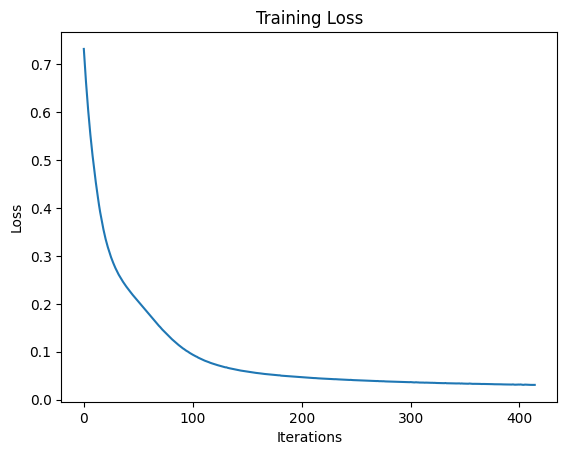

Improvement: Use regularization, dropout and early stopping.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = MLPClassifier(hidden_layer_sizes=(100, 100),
                      max_iter=2000, random_state=42)

model.fit(X_train, y_train)

train_acc = accuracy_score(y_train, model.predict(X_train))
test_acc = accuracy_score(y_test, model.predict(X_test))

print("Training Accuracy:", train_acc)
print("Testing Accuracy:", test_acc)
print("Training Error:", 1 - train_acc)
print("Testing Error:", 1 - test_acc)

plt.plot(model.loss_curve_)
plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

print("Improvement: Use regularization, dropout and early stopping.")

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

np.random.seed(42)

X = np.linspace(0, 10, 100).reshape(-1, 1)
y = 3 * X[:, 0]**2 + 2 * X[:, 0] + np.random.randn(100) * 10

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

for degree in [1, 2, 5, 10]:
    poly = PolynomialFeatures(degree=degree)

    X1 = poly.fit_transform(X_train)
    X2 = poly.transform(X_test)

    model = LinearRegression()
    model.fit(X1, y_train)

    train_error = mean_squared_error(y_train, model.predict(X1))
    test_error = mean_squared_error(y_test, model.predict(X2))

    print("\nDegree:", degree)
    print("Training Error:", train_error)
    print("Testing Error:", test_error)


Degree: 1
Training Error: 651.15783897876
Testing Error: 544.1736611263532

Degree: 2
Training Error: 86.02578316535057
Testing Error: 61.96330450394994

Degree: 5
Training Error: 79.71842090201632
Testing Error: 64.91260437956578

Degree: 10
Training Error: 74.93059403801581
Testing Error: 81.72816371161379


In [3]:
import numpy as np
from sklearn.datasets import make_regression
from sklearn.linear_model import Lasso, Ridge
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error

X, y = make_regression(n_samples=200, n_features=10,
                       noise=20, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

l1 = Lasso(alpha=1.0)
l2 = Ridge(alpha=1.0)

l1.fit(X_train, y_train)
l2.fit(X_train, y_train)

print("L1 Coefficients:", l1.coef_)
print("L2 Coefficients:", l2.coef_)

print("L1 MSE:", mean_squared_error(y_test, l1.predict(X_test)))
print("L2 MSE:", mean_squared_error(y_test, l2.predict(X_test)))

print("L1 Zero Coefficients:", np.sum(l1.coef_ == 0))

L1 Coefficients: [31.13009108 34.27251339  7.02396417 92.56179795  8.73225852 92.10401034
 39.1524667  79.13291621 50.70970915  7.10809801]
L2 Coefficients: [31.82206527 35.16494008  8.01633556 92.87704784  9.53349134 92.68245932
 40.19158538 79.59335314 51.41151822  7.99401766]
L1 MSE: 427.4515201553146
L2 MSE: 417.4994692985253
L1 Zero Coefficients: 0



Learning Rate: 0.001
Final Weight: 1.7837702359447907
Final Loss: 0.5377072899254832

Learning Rate: 0.01
Final Weight: 1.9999999999676041
Final Loss: 1.8975159593291566e-20

Learning Rate: 0.1
Final Weight: -165635947.04403096
Final Loss: 2.0957496095339248e+17


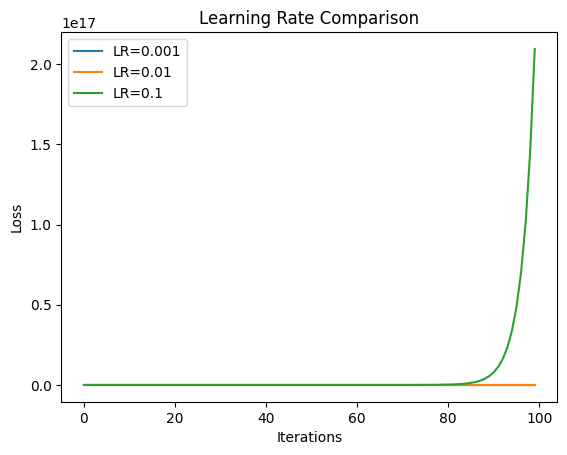

In [4]:
import numpy as np
import matplotlib.pyplot as plt

X = np.array([1, 2, 3, 4, 5])
y = np.array([2, 4, 6, 8, 10])

for lr in [0.001, 0.01, 0.1]:
    w = 0
    losses = []

    for i in range(100):
        pred = w * X
        error = pred - y

        loss = np.mean(error ** 2)
        losses.append(loss)

        gradient = 2 * np.mean(error * X)
        w = w - lr * gradient

    print("\nLearning Rate:", lr)
    print("Final Weight:", w)
    print("Final Loss:", losses[-1])

    plt.plot(losses, label=f"LR={lr}")

plt.xlabel("Iterations")
plt.ylabel("Loss")
plt.title("Learning Rate Comparison")
plt.legend()
plt.show()

In [5]:
import numpy as np

a = np.float16(0.1)
b = np.float32(0.1)
c = np.float64(0.1)

print("Float16:", a)
print("Float32:", b)
print("Float64:", c)

x = np.float32(0.1)
y = np.float32(0.2)

print("\nFloat32 Addition:", x + y)
print("Float32 Precision:", (x + y) == np.float32(0.3))

x = np.float64(0.1)
y = np.float64(0.2)

print("\nFloat64 Addition:", x + y)
print("Float64 Precision:", (x + y) == np.float64(0.3))

print("\nFloat16:", np.float16(1/3))
print("Float32:", np.float32(1/3))
print("Float64:", np.float64(1/3))

Float16: 0.1
Float32: 0.1
Float64: 0.1

Float32 Addition: 0.3
Float32 Precision: True

Float64 Addition: 0.30000000000000004
Float64 Precision: False

Float16: 0.3333
Float32: 0.33333334
Float64: 0.3333333333333333


In [6]:
!pip install scikit-optimize

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [scikit-optimize]


In [7]:
import numpy as np
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from skopt import BayesSearchCV

X, y = load_breast_cancer(return_X_y=True)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(random_state=42)

params = {
    'n_estimators': [50, 100, 150],
    'max_depth': [3, 5, 10, None]
}

# Grid Search
grid = GridSearchCV(model, params, cv=3)
grid.fit(X_train, y_train)

# Random Search
random = RandomizedSearchCV(
    model, params, n_iter=5, cv=3, random_state=42
)
random.fit(X_train, y_train)

# Bayesian Optimization
bayes = BayesSearchCV(
    model,
    {
        'n_estimators': (50, 150),
        'max_depth': (3, 15)
    },
    n_iter=10,
    cv=3,
    random_state=42
)
bayes.fit(X_train, y_train)

for name, result in [
    ("Grid Search", grid),
    ("Random Search", random),
    ("Bayesian Optimization", bayes)
]:
    pred = result.predict(X_test)
    print("\n", name)
    print("Best Parameters:", result.best_params_)
    print("Accuracy:", accuracy_score(y_test, pred))


 Grid Search
Best Parameters: {'max_depth': 10, 'n_estimators': 50}
Accuracy: 0.9649122807017544

 Random Search
Best Parameters: {'n_estimators': 50, 'max_depth': None}
Accuracy: 0.9649122807017544

 Bayesian Optimization
Best Parameters: OrderedDict({'max_depth': 8, 'n_estimators': 123})
Accuracy: 0.9649122807017544


In [8]:
import numpy as np
import random

states = 4
actions = 2

Q = np.zeros((states, actions))

alpha = 0.1
gamma = 0.9
epsilon = 0.1

for episode in range(1000):

    state = random.randint(0, states - 1)

    for step in range(20):

        if random.random() < epsilon:
            action = random.randint(0, 1)
        else:
            action = np.argmax(Q[state])

        # Simulated traffic environment
        next_state = random.randint(0, states - 1)

        if action == 0:
            reward = 10 if next_state < state else -5
        else:
            reward = 10 if next_state > state else -5

        Q[state, action] = Q[state, action] + alpha * (
            reward + gamma * np.max(Q[next_state]) - Q[state, action]
        )

        state = next_state

print("Learned Q Table:")
print(Q)

print("\nTraffic Signal Decisions:")
for state in range(states):
    action = np.argmax(Q[state])

    if action == 0:
        print("State", state, ": Green Signal - Road 1")
    else:
        print("State", state, ": Green Signal - Road 2")

Learned Q Table:
[[36.52855413 51.16591814]
 [42.91963049 40.29535161]
 [45.68478091 40.41118602]
 [49.07305257 37.1990833 ]]

Traffic Signal Decisions:
State 0 : Green Signal - Road 2
State 1 : Green Signal - Road 1
State 2 : Green Signal - Road 1
State 3 : Green Signal - Road 1


In [9]:
import numpy as np
from sklearn.linear_model import Perceptron
from sklearn.preprocessing import StandardScaler

# Income and credit score
X = np.array([
    [20000, 500],
    [25000, 550],
    [30000, 600],
    [40000, 650],
    [50000, 700],
    [60000, 750]
])

# 0 = Ineligible, 1 = Eligible
y = np.array([0, 0, 0, 1, 1, 1])

scaler = StandardScaler()
X = scaler.fit_transform(X)

model = Perceptron(max_iter=1000, random_state=42)
model.fit(X, y)

test = np.array([[45000, 680]])
test = scaler.transform(test)

prediction = model.predict(test)

if prediction[0] == 1:
    print("Loan Applicant: Eligible")
else:
    print("Loan Applicant: Ineligible")

Loan Applicant: Eligible


In [10]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

y = np.array([0, 1, 1, 0])

model = Sequential([
    Dense(4, input_dim=2, activation='tanh'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X, y, epochs=1000, verbose=0)

predictions = model.predict(X, verbose=0)

print("XOR Predictions:")
for i in range(4):
    print(X[i], "=", round(float(predictions[i][0])))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


XOR Predictions:
[0 0] = 0
[0 1] = 1
[1 0] = 1
[1 1] = 0


In [11]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.utils import to_categorical

iris = load_iris()

X = iris.data
y = to_categorical(iris.target)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = Sequential([
    Dense(16, activation='relu', input_shape=(4,)),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

model.fit(X_train, y_train, epochs=100, verbose=0)

loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

pred = model.predict(X_test, verbose=0)
print("Predicted Classes:", pred.argmax(axis=1))

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Test Loss: 0.09963551163673401
Test Accuracy: 1.0
Predicted Classes: [1 0 2 1 1 0 1 2 1 1 2 0 0 0 0 1 2 1 1 2 0 2 0 2 2 2 2 2 0 0]


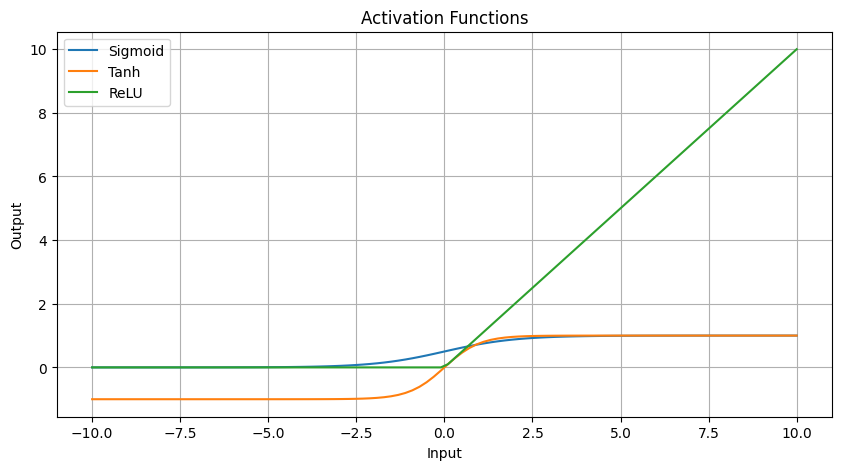

Sigmoid: [4.53978687e-05 5.55606489e-05 6.79983174e-05 8.32200197e-05
 1.01848815e-04]
Tanh: [-1.         -0.99999999 -0.99999999 -0.99999999 -0.99999998]
ReLU: [0. 0. 0. 0. 0.]


In [12]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-x))
tanh = np.tanh(x)
relu = np.maximum(0, x)

plt.figure(figsize=(10, 5))

plt.plot(x, sigmoid, label="Sigmoid")
plt.plot(x, tanh, label="Tanh")
plt.plot(x, relu, label="ReLU")

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Activation Functions")
plt.legend()
plt.grid()
plt.show()

print("Sigmoid:", sigmoid[:5])
print("Tanh:", tanh[:5])
print("ReLU:", relu[:5])

In [13]:
import numpy as np
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for activation in ['relu', 'sigmoid', 'tanh']:

    model = Sequential([
        Dense(16, activation=activation, input_shape=(2,)),
        Dense(8, activation=activation),
        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    model.fit(X_train, y_train, epochs=50, verbose=0)

    loss, accuracy = model.evaluate(X_test, y_test, verbose=0)

    print("\nActivation:", activation)
    print("Test Loss:", loss)
    print("Test Accuracy:", accuracy)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Activation: relu
Test Loss: 0.21790874004364014
Test Accuracy: 0.8899999856948853

Activation: sigmoid
Test Loss: 0.43788060545921326
Test Accuracy: 0.8600000143051147

Activation: tanh
Test Loss: 0.2914486825466156
Test Accuracy: 0.8600000143051147


In [14]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Input
X = np.array([[1, 2]])

# Hidden layer weights
W1 = np.array([
    [0.1, 0.2],
    [0.3, 0.4]
])

b1 = np.array([0.1, 0.1])

# Output layer weights
W2 = np.array([
    [0.5],
    [0.6]
])

b2 = np.array([0.1])

# Hidden layer calculation
hidden = sigmoid(np.dot(X, W1) + b1)

print("Hidden Layer Output:")
print(hidden)

# Output layer calculation
output = sigmoid(np.dot(hidden, W2) + b2)

print("Final Output:")
print(output)

Hidden Layer Output:
[[0.68997448 0.75026011]]
Final Output:
[[0.70995043]]


In [15]:
import numpy as np

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

# Input and target
X = np.array([[1, 0]])
y = np.array([[1]])

# Initial weights
W1 = np.array([[0.2, 0.3],
               [0.4, 0.5]])

W2 = np.array([[0.6],
               [0.7]])

learning_rate = 0.1

# Forward propagation
h = sigmoid(np.dot(X, W1))
output = sigmoid(np.dot(h, W2))

print("Before Update:", output)

# Calculate output error
error = output - y

# Output gradient
d_output = error * output * (1 - output)

# Hidden layer gradient
d_hidden = np.dot(d_output, W2.T) * h * (1 - h)

# Update weights
W2 = W2 - learning_rate * np.dot(h.T, d_output)
W1 = W1 - learning_rate * np.dot(X.T, d_hidden)

# New prediction
h = sigmoid(np.dot(X, W1))
new_output = sigmoid(np.dot(h, W2))

print("Updated W1:")
print(W1)

print("Updated W2:")
print(W2)

print("After Update:", new_output)

Before Update: [[0.67524623]]
Updated W1:
[[0.20105761 0.30121863]
 [0.4        0.5       ]]
Updated W2:
[[0.60391563]
 [0.70409088]]
After Update: [[0.67631342]]


In [16]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# House size and number of bedrooms
X = np.array([
    [1000, 2],
    [1200, 2],
    [1500, 3],
    [1800, 3],
    [2000, 4],
    [2500, 4]
])

# House prices in lakhs
y = np.array([30, 35, 45, 50, 60, 75])

model = Sequential([
    Dense(16, activation='relu', input_shape=(2,)),
    Dense(8, activation='relu'),
    Dense(1)
])

model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.fit(X, y, epochs=200, verbose=0)

predictions = model.predict(X, verbose=0)

print("Actual Price | Predicted Price")

for i in range(len(y)):
    print(y[i], " | ", round(float(predictions[i][0]), 2))

print("Final MSE:", model.evaluate(X, y, verbose=0))

Actual Price | Predicted Price
30  |  29.57
35  |  35.47
45  |  44.32
50  |  53.17
60  |  59.08
75  |  73.82
Final MSE: 2.1918115615844727


In [17]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from sklearn.metrics import accuracy_score

# Transaction features: Amount and transaction frequency
X = np.array([
    [100, 1],
    [200, 2],
    [150, 1],
    [5000, 10],
    [6000, 12],
    [7000, 15],
    [120, 1],
    [8000, 20]
], dtype=float)

# 0 = Legitimate, 1 = Fraud
y = np.array([0, 0, 0, 1, 1, 1, 0, 1])

# Normalize input
X = X / np.max(X, axis=0)

model = Sequential([
    Dense(8, activation='relu', input_shape=(2,)),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.fit(X, y, epochs=200, verbose=0)

predictions = model.predict(X, verbose=0)

classes = (predictions >= 0.5).astype(int).flatten()

print("Actual Values:", y)
print("Predicted Values:", classes)

print("Accuracy:", accuracy_score(y, classes))

# Binary Cross Entropy calculation
epsilon = 1e-7
p = np.clip(predictions.flatten(), epsilon, 1 - epsilon)

bce = -np.mean(y * np.log(p) + (1-y) * np.log(1-p))

print("Binary Cross Entropy Loss:", bce)

Actual Values: [0 0 0 1 1 1 0 1]
Predicted Values: [0 0 0 0 0 0 0 0]
Accuracy: 0.5
Binary Cross Entropy Loss: 0.693147212266922
